# Tugas Praktikum 4: Association Rule
Dataset: Online Retail (UCI Machine Learning Repository), berisi transaksi ritel online sebuah toko di Inggris periode Desember 2010 sampai Desember 2011, meliputi nomor invoice, kode dan deskripsi produk, jumlah, harga, ID pelanggan, serta negara.

Link: https://archive.ics.uci.edu/dataset/352/online+retail

# 1. Import Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_excel("Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


# 2. Eksplorasi dan Pembersihan Data (EDA)

## Identifikasi Kolom yang Relevan
Association Rule hanya membutuhkan informasi transaksi dan item yang dibeli. Kolom InvoiceNo digunakan sebagai identitas transaksi, sedangkan Description menunjukkan nama produk. Kolom Quantity, StockCode, dan UnitPrice digunakan untuk proses pembersihan data, seperti menghapus transaksi dengan kuantitas ≤ 0, item non-produk, dan harga 0. Sementara itu, CustomerID, InvoiceDate, dan Country tidak digunakan. Baris dengan CustomerID kosong tetap dipertahankan karena transaksinya masih valid.

## 2.1 Eksplorasi Awal

In [5]:
# Jumlah nilai kosong per kolom
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
# Statistik deskriptif kolom numerik
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
# Jumlah nilai unik setiap kolom
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [8]:
# Ubah InvoiceNo ke string agar bisa dicek awalan huruf 'C'
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

print("Jumlah transaksi dibatalkan (InvoiceNo diawali 'C'):", df["InvoiceNo"].str.startswith("C").sum(), "baris")
print("Jumlah baris dengan Quantity <= 0                 :", (df["Quantity"] <= 0).sum(), "baris")
print("Jumlah baris dengan Description kosong           :", df["Description"].isnull().sum(), "baris")

Jumlah transaksi dibatalkan (InvoiceNo diawali 'C'): 9288 baris
Jumlah baris dengan Quantity <= 0                 : 10624 baris
Jumlah baris dengan Description kosong           : 1454 baris


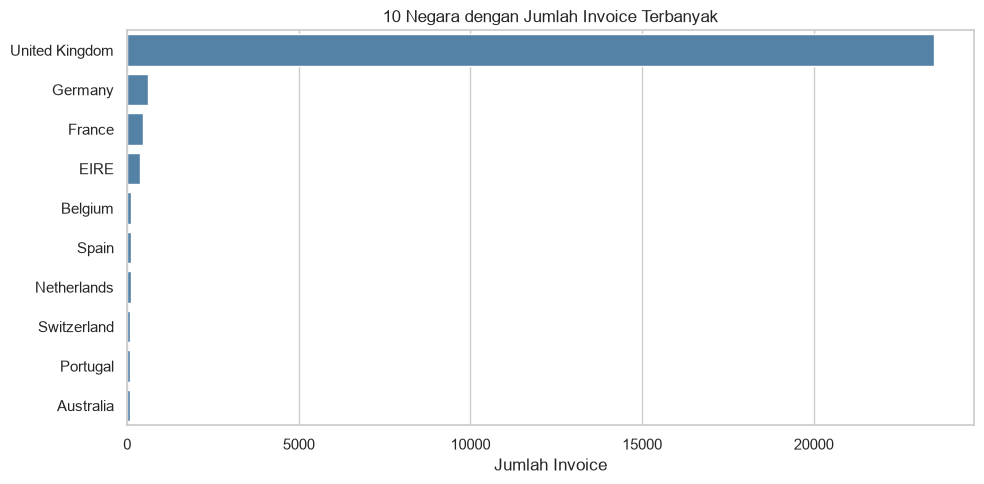

In [9]:
# 10 negara dengan jumlah invoice terbanyak
top_country = df.groupby("Country")["InvoiceNo"].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_country.values, y=top_country.index, color="steelblue")
plt.title("10 Negara dengan Jumlah Invoice Terbanyak")
plt.xlabel("Jumlah Invoice")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 2.2 Pembersihan Data

In [10]:
# Kondisi sebelum pembersihan
baris_awal = df.shape[0]
invoice_awal = df["InvoiceNo"].nunique()
print(f"Sebelum pembersihan: {baris_awal:,} baris, {invoice_awal:,} invoice")

Sebelum pembersihan: 541,909 baris, 25,900 invoice


In [11]:
df_clean = df.copy()
log = [("Data awal", df_clean.shape[0], df_clean["InvoiceNo"].nunique())]

# 1) Hapus baris dengan Description kosong
df_clean = df_clean.dropna(subset=["Description"])
log.append(("Hapus Description kosong", df_clean.shape[0], df_clean["InvoiceNo"].nunique()))

# 2) Hapus transaksi yang dibatalkan (InvoiceNo diawali 'C')
df_clean = df_clean[~df_clean["InvoiceNo"].str.startswith("C")]
log.append(("Hapus invoice batal (C...)", df_clean.shape[0], df_clean["InvoiceNo"].nunique()))

# 3) Hapus Quantity negatif atau nol
df_clean = df_clean[df_clean["Quantity"] > 0]
log.append(("Hapus Quantity <= 0", df_clean.shape[0], df_clean["InvoiceNo"].nunique()))

In [12]:
# Lihat StockCode yang hanya berupa huruf (biasanya bukan produk)
df_clean[df_clean["StockCode"].astype(str).str.fullmatch(r"[A-Za-z]+")] \
    .groupby(["StockCode", "Description"]).size()

StockCode  Description               
AMAZONFEE  AMAZON FEE                       2
B          Adjust bad debt                  3
DCGSSBOY   BOYS PARTY BAG                  11
DCGSSGIRL  GIRLS PARTY BAG                 13
DOT        DOTCOM POSTAGE                 708
M          Manual                         327
PADS       PADS TO MATCH ALL CUSHIONS       4
POST       POSTAGE                       1126
S          SAMPLES                          2
m          Manual                           1
dtype: int64

In [13]:
# 4) Rapikan spasi pada Description
df_clean["Description"] = df_clean["Description"].str.strip()

# 5) Hapus UnitPrice <= 0
df_clean = df_clean[df_clean["UnitPrice"] > 0]
log.append(("Hapus UnitPrice <= 0", df_clean.shape[0], df_clean["InvoiceNo"].nunique()))

# 6) Hapus item non-produk
non_produk = ["POST", "DOT", "M", "m", "B", "AMAZONFEE", "S", "CRUK", "D", "BANK CHARGES"]
df_clean = df_clean[~df_clean["StockCode"].astype(str).isin(non_produk)]
log.append(("Hapus item non-produk", df_clean.shape[0], df_clean["InvoiceNo"].nunique()))

ringkasan = pd.DataFrame(log, columns=["Tahap", "Jumlah Baris", "Jumlah Invoice"])
ringkasan["Baris Terhapus"] = (-ringkasan["Jumlah Baris"].diff()).fillna(0).astype(int)
ringkasan

,Tahap,Jumlah Baris,Jumlah Invoice,Baris Terhapus
0,Data awal,541909,25900,0
1,Hapus Description kosong,540455,24446,1454
2,Hapus invoice batal (C...),531167,20610,9288
3,Hapus Quantity <= 0,530693,20136,474
4,Hapus UnitPrice <= 0,530104,19960,589
5,Hapus item non-produk,527933,19776,2171


In [14]:
print(f"Sebelum pembersihan : {baris_awal:,} baris | {invoice_awal:,} invoice")
print(f"Sesudah pembersihan : {df_clean.shape[0]:,} baris | {df_clean['InvoiceNo'].nunique():,} invoice")
print(f"Baris terhapus      : {baris_awal - df_clean.shape[0]:,} ({(baris_awal - df_clean.shape[0]) / baris_awal:.2%})")
print(f"Invoice terhapus    : {invoice_awal - df_clean['InvoiceNo'].nunique():,}")

Sebelum pembersihan : 541,909 baris | 25,900 invoice
Sesudah pembersihan : 527,933 baris | 19,776 invoice
Baris terhapus      : 13,976 (2.58%)
Invoice terhapus    : 6,124


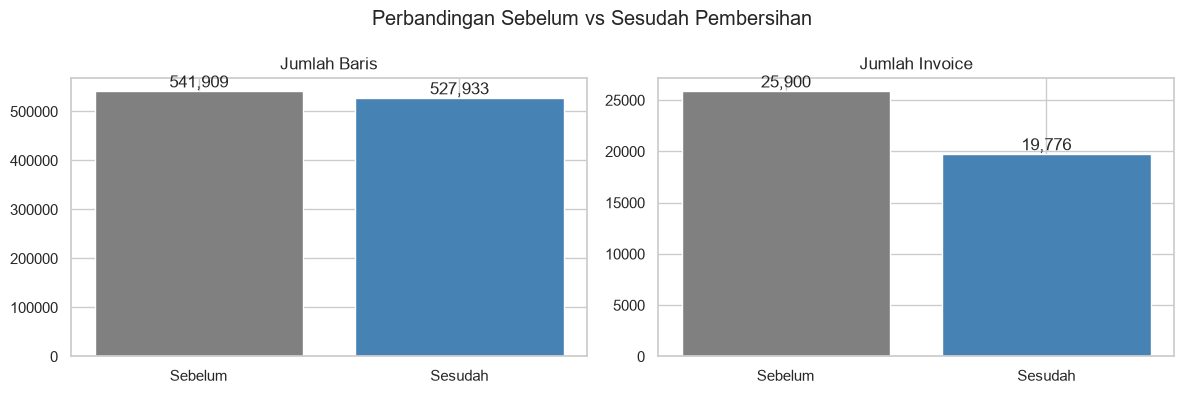

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["Sebelum", "Sesudah"], [baris_awal, df_clean.shape[0]], color=["gray", "steelblue"])
ax[0].set_title("Jumlah Baris")
ax[1].bar(["Sebelum", "Sesudah"], [invoice_awal, df_clean["InvoiceNo"].nunique()], color=["gray", "steelblue"])
ax[1].set_title("Jumlah Invoice")
for a in ax:
    for p in a.patches:
        a.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")
plt.suptitle("Perbandingan Sebelum vs Sesudah Pembersihan")
plt.tight_layout()
plt.show()

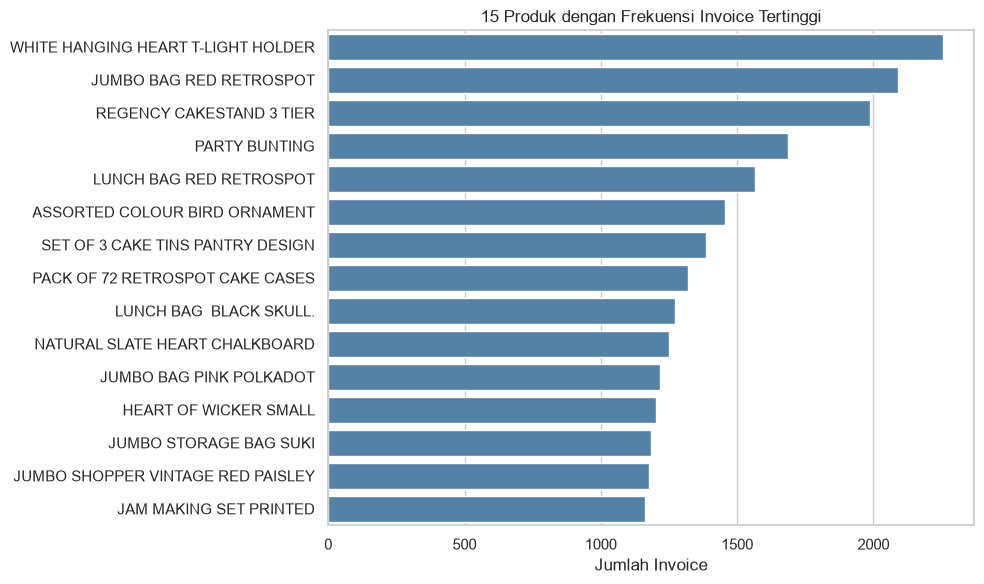

In [16]:
# 15 produk yang paling sering muncul di invoice (setelah dibersihkan)
top_items = df_clean.groupby("Description")["InvoiceNo"].nunique().sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_items.values, y=top_items.index, color="steelblue")
plt.title("15 Produk dengan Frekuensi Invoice Tertinggi")
plt.xlabel("Jumlah Invoice")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 3. Persiapan Data untuk Association Rule
## 3.1 Format Transaksi Berbasis Invoice

In [17]:
transactions = df_clean.groupby("InvoiceNo")["Description"].apply(lambda x: sorted(set(x)))
print("Jumlah transaksi:", len(transactions))
transactions.head()

Jumlah transaksi: 19776


InvoiceNo
536365    [CREAM CUPID HEARTS COAT HANGER, GLASS STAR FROSTED T-LIGHT HOLDER, KNITTED ...
536366                                [HAND WARMER RED POLKA DOT, HAND WARMER UNION JACK]
536367    [ASSORTED COLOUR BIRD ORNAMENT, BOX OF 6 ASSORTED COLOUR TEASPOONS, BOX OF V...
536368    [BLUE COAT RACK PARIS FASHION, JAM MAKING SET WITH JARS, RED COAT RACK PARIS...
536369                                                         [BATH BUILDING BLOCK WORD]
Name: Description, dtype: object

count    19776.000000
mean        26.151446
std         46.980538
min          1.000000
25%          6.000000
50%         15.000000
75%         29.000000
max       1107.000000
Name: Description, dtype: float64


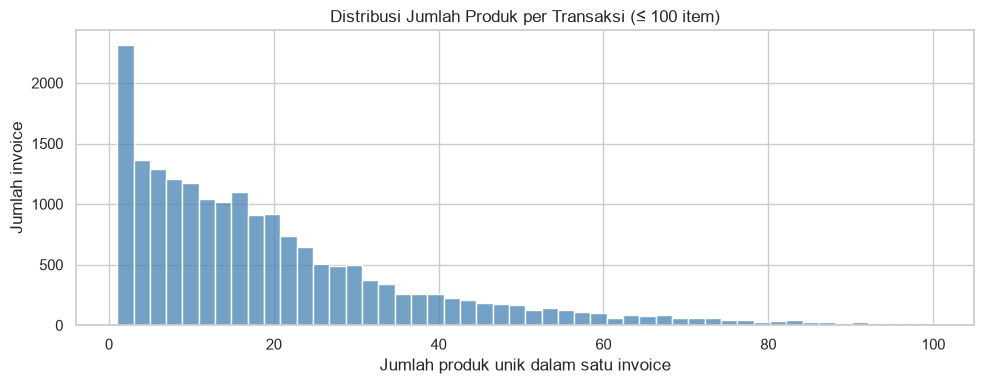

In [18]:
basket_size = transactions.apply(len)
print(basket_size.describe())

plt.figure(figsize=(10, 4))
sns.histplot(basket_size[basket_size <= 100], bins=50, color="steelblue")
plt.title("Distribusi Jumlah Produk per Transaksi (≤ 100 item)")
plt.xlabel("Jumlah produk unik dalam satu invoice")
plt.ylabel("Jumlah invoice")
plt.tight_layout()
plt.show()

## 3.2 One-Hot Encoding (Basket)

In [19]:
te = TransactionEncoder()
te_array = te.fit(transactions.tolist()).transform(transactions.tolist())
basket = pd.DataFrame(te_array, columns=te.columns_, index=transactions.index)

print("Ukuran basket (invoice x produk):", basket.shape)
basket.iloc[:5, :8]

Ukuran basket (invoice x produk): (19776, 4008)


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


In [20]:
# Tingkat kepadatan matriks: proporsi sel bernilai True
print(f"Density basket: {basket.values.mean():.4%}")

Density basket: 0.6525%


# 4. Penerapan Algoritma
## 4.1 Pemilihan Algoritma
Algoritma yang digunakan adalah FP-Growth. Alasannya adalah basket berukuran ±19.800 transaksi × ±4.000 produk. Implementasi Apriori di mlxtend membangkitkan kandidat itemset secara eksplisit sehingga pada data ini membutuhkan memori sangat besar (uji coba di lingkungan pengerjaan meminta alokasi ±12 GB dan gagal). FP-Growth menghasilkan frequent itemset yang identik dengan Apriori, tetapi tanpa membangkitkan kandidat (memakai struktur FP-tree) sehingga jauh lebih cepat dan hemat memori.

## 4.2 Titik Awal: min_support = 0.01, min_confidence = 0.5

In [21]:
%%time
frequent_itemsets = fpgrowth(basket, min_support=0.01, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

print("Jumlah frequent itemset:", len(frequent_itemsets))
frequent_itemsets["length"].value_counts().sort_index()

Jumlah frequent itemset: 1874
CPU times: total: 15.3 s
Wall time: 26.5 s


length
1    822
2    816
3    218
4     17
5      1
Name: count, dtype: int64

In [22]:
frequent_itemsets.sort_values("support", ascending=False).head(10)

,support,itemsets,length
0,0.114078,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
94,0.105633,frozenset({JUMBO BAG RED RETROSPOT}),1
306,0.100526,frozenset({REGENCY CAKESTAND 3 TIER}),1
601,0.085204,frozenset({PARTY BUNTING}),1
42,0.079086,frozenset({LUNCH BAG RED RETROSPOT}),1
7,0.073574,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
633,0.070034,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
43,0.066748,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
176,0.064371,frozenset({LUNCH BAG BLACK SKULL.}),1
81,0.063157,frozenset({NATURAL SLATE HEART CHALKBOARD}),1


In [23]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print("Jumlah aturan (support >= 0.01, confidence >= 0.5):", len(rules))
rules[["antecedents", "consequents", "support", "confidence", "lift"]].head()

Jumlah aturan (support >= 0.01, confidence >= 0.5): 841


,antecedents,consequents,support,confidence,lift
0,frozenset({POPPY'S PLAYHOUSE KITCHEN}),frozenset({POPPY'S PLAYHOUSE BEDROOM}),0.015827,0.717890,33.562626
1,frozenset({POPPY'S PLAYHOUSE BEDROOM}),frozenset({POPPY'S PLAYHOUSE KITCHEN}),0.015827,0.739953,33.562626
2,"frozenset({JAM MAKING SET WITH JARS, SET OF 3 CAKE TINS PANTRY DESIGN})",frozenset({JAM MAKING SET PRINTED}),0.010417,0.542105,9.226053
3,"frozenset({JAM MAKING SET PRINTED, SET OF 3 CAKE TINS PANTRY DESIGN})",frozenset({JAM MAKING SET WITH JARS}),0.010417,0.593660,10.371218
4,frozenset({ALARM CLOCK BAKELIKE RED}),frozenset({ALARM CLOCK BAKELIKE GREEN}),0.032362,0.608944,12.288239


## 4.3 Analisis Sensitivitas Parameter

In [24]:
grid = []
for sup in [0.005, 0.01, 0.015, 0.02, 0.03]:
    fi = fpgrowth(basket, min_support=sup, use_colnames=True)
    for conf in [0.3, 0.5, 0.6, 0.7, 0.8]:
        r = association_rules(fi, metric="confidence", min_threshold=conf)
        grid.append({"min_support": sup, "min_confidence": conf, "jumlah_itemset": len(fi), "jumlah_aturan": len(r)})

grid = pd.DataFrame(grid)
pivot = grid.pivot(index="min_support", columns="min_confidence", values="jumlah_aturan")
pivot

min_confidence,0.3,0.5,0.6,0.7,0.8
min_support,,,,,
0.005,36950,20725,14178,8611,3921
0.010,1707,841,503,265,105
0.015,432,187,98,46,17
0.020,152,60,30,13,5
0.030,18,13,9,4,1


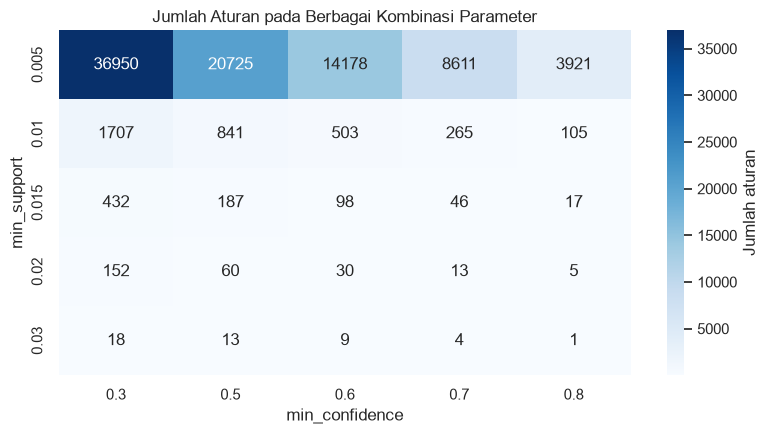

In [25]:
plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Jumlah aturan"})
plt.title("Jumlah Aturan pada Berbagai Kombinasi Parameter")
plt.xlabel("min_confidence")
plt.ylabel("min_support")
plt.tight_layout()
plt.show()

In [26]:
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.6

frequent_itemsets = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules_final = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
rules_final = rules_final[rules_final["lift"] > 1].sort_values("lift", ascending=False).reset_index(drop=True)

print(f"Jumlah aturan final (support >= {MIN_SUPPORT}, confidence >= {MIN_CONFIDENCE}, lift > 1): {len(rules_final)}")

Jumlah aturan final (support >= 0.01, confidence >= 0.6, lift > 1): 503


# 5. Evaluasi Aturan Asosiasi
## 5.1 Daftar Aturan beserta Support, Confidence, dan Lift

In [27]:
def fs_to_str(fs):
    return ", ".join(sorted(fs))

rules_view = rules_final.copy()
rules_view["antecedents"] = rules_view["antecedents"].apply(fs_to_str)
rules_view["consequents"] = rules_view["consequents"].apply(fs_to_str)
rules_view = rules_view[["antecedents", "consequents", "antecedent support", "consequent support",
                         "support", "confidence", "lift"]].round(4)
rules_view.head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0109,0.0120,0.0103,0.9442,78.7858
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.0120,0.0109,0.0103,0.8565,78.7858
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.0121,0.0108,0.0103,0.8458,78.5315
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.0108,0.0121,0.0103,0.9531,78.5315
4,HERB MARKER ROSEMARY,"HERB MARKER BASIL, HERB MARKER THYME",0.0121,0.0106,0.0101,0.8333,78.4762
5,"HERB MARKER BASIL, HERB MARKER THYME",HERB MARKER ROSEMARY,0.0106,0.0121,0.0101,0.9524,78.4762
6,"HERB MARKER BASIL, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0108,0.0120,0.0101,0.9346,77.9841
7,HERB MARKER THYME,"HERB MARKER BASIL, HERB MARKER ROSEMARY",0.0120,0.0108,0.0101,0.8439,77.9841
8,HERB MARKER THYME,HERB MARKER ROSEMARY,0.0120,0.0121,0.0112,0.9325,76.8371
9,HERB MARKER ROSEMARY,HERB MARKER THYME,0.0121,0.0120,0.0112,0.9208,76.8371


In [28]:
rules_view[["support", "confidence", "lift"]].describe()

,support,confidence,lift
count,503.000000,503.000000,503.000000
mean,0.013267,0.721992,20.514742
std,0.004519,0.088269,17.233817
min,0.010000,0.600000,5.689700
25%,0.010550,0.647350,10.226300
50%,0.011800,0.708500,14.799800
75%,0.014100,0.778400,22.676550
max,0.041700,0.953100,78.785800


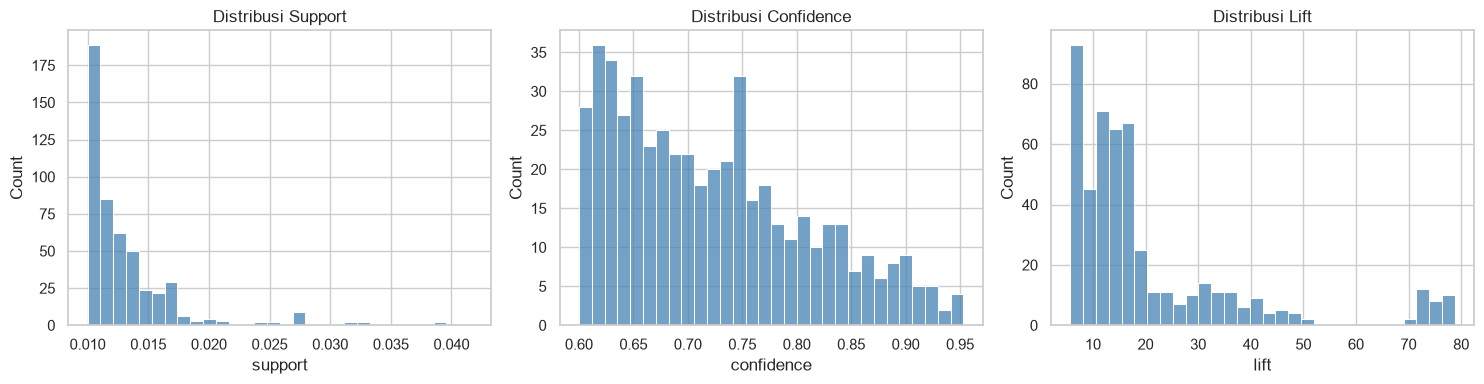

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rules_view["support"], bins=30, ax=ax[0], color="steelblue")
ax[0].set_title("Distribusi Support")
sns.histplot(rules_view["confidence"], bins=30, ax=ax[1], color="steelblue")
ax[1].set_title("Distribusi Confidence")
sns.histplot(rules_view["lift"], bins=30, ax=ax[2], color="steelblue")
ax[2].set_title("Distribusi Lift")
plt.tight_layout()
plt.show()

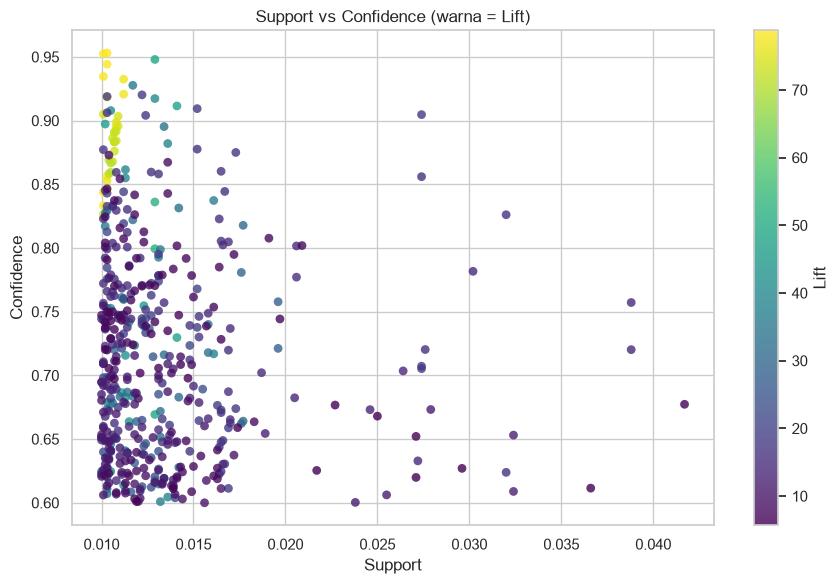

In [30]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(rules_view["support"], rules_view["confidence"], c=rules_view["lift"],
                 cmap="viridis", s=40, alpha=0.8, edgecolors="none")
plt.colorbar(sc, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support vs Confidence (warna = Lift)")
plt.tight_layout()
plt.show()

## 5.2 Tiga Aturan Terbaik Berdasarkan Lift
Jika diurutkan murni berdasarkan lift, beberapa aturan teratas biasanya berasal dari kelompok produk yang sama (aturan simetris A→B dan B→A memiliki lift yang sama). Karena itu ditampilkan dua versi:
1. Top-3 murni berdasarkan lift.
2. Top-3 dari kelompok produk yang berbeda (satu aturan terbaik per kombinasi item), agar interpretasi lebih beragam dan berguna.

In [31]:
# Versi 1: top-3 murni berdasarkan lift
rules_view.head(3)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0109,0.0120,0.0103,0.9442,78.7858
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.0120,0.0109,0.0103,0.8565,78.7858
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.0121,0.0108,0.0103,0.8458,78.5315


In [32]:
# Versi 2: top-3 dari kelompok produk berbeda
# "Keluarga" produk = dua kata pertama nama produk, mis. "HERB MARKER", "REGENCY TEA", "POPPY'S PLAYHOUSE"
def family(item):
    return " ".join(item.split()[:2])

rv = rules_final.copy()
rv["families"] = rv.apply(lambda r: {family(i) for i in r["antecedents"] | r["consequents"]}, axis=1)

picked, used_families = [], set()
for _, r in rv.sort_values(["lift", "confidence"], ascending=False).iterrows():
    if r["families"] & used_families:    # lewati jika keluarga produk sudah terwakili
        continue
    picked.append(r)
    used_families |= r["families"]
    if len(picked) == 3:
        break

top3 = pd.DataFrame(picked)[["antecedents", "consequents", "support", "confidence", "lift"]]
top3["antecedents"] = top3["antecedents"].apply(fs_to_str)
top3["consequents"] = top3["consequents"].apply(fs_to_str)
top3 = top3.round(4).reset_index(drop=True)
top3.index = top3.index + 1
top3

,antecedents,consequents,support,confidence,lift
1,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0103,0.9442,78.7858
2,"REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES",REGENCY TEA PLATE PINK,0.0129,0.7994,51.8308
3,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.0111,0.7474,46.3366


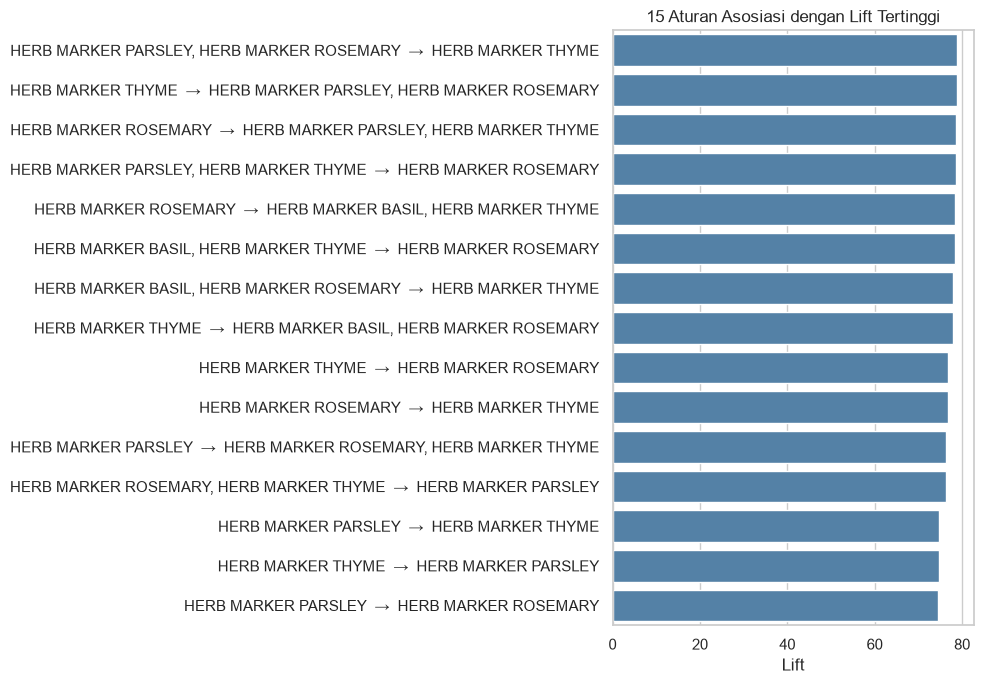

In [33]:
# Visualisasi 15 aturan teratas berdasarkan lift
top15 = rules_view.head(15).copy()
top15["rule"] = top15["antecedents"] + "  →  " + top15["consequents"]

plt.figure(figsize=(10, 7))
sns.barplot(data=top15, x="lift", y="rule", color="steelblue")
plt.title("15 Aturan Asosiasi dengan Lift Tertinggi")
plt.xlabel("Lift")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [34]:
# Cetak interpretasi otomatis untuk tiga aturan terbaik
n_trx = len(basket)
for i, r in top3.iterrows():
    print(f"Aturan {i}: {{{r['antecedents']}}} -> {{{r['consequents']}}}")
    print(f"  - Support    {r['support']:.4f}: kombinasi ini muncul di {r['support']:.2%} transaksi (≈ {round(r['support'] * n_trx)} invoice).")
    print(f"  - Confidence {r['confidence']:.4f}: {r['confidence']:.0%} pembeli antecedent juga membeli consequent.")
    print(f"  - Lift       {r['lift']:.2f}: peluang membeli consequent {r['lift']:.1f}x lebih tinggi jika antecedent dibeli.")
    print()

Aturan 1: {HERB MARKER PARSLEY, HERB MARKER ROSEMARY} -> {HERB MARKER THYME}
  - Support    0.0103: kombinasi ini muncul di 1.03% transaksi (≈ 204 invoice).
  - Confidence 0.9442: 94% pembeli antecedent juga membeli consequent.
  - Lift       78.79: peluang membeli consequent 78.8x lebih tinggi jika antecedent dibeli.

Aturan 2: {REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES} -> {REGENCY TEA PLATE PINK}
  - Support    0.0129: kombinasi ini muncul di 1.29% transaksi (≈ 255 invoice).
  - Confidence 0.7994: 80% pembeli antecedent juga membeli consequent.
  - Lift       51.83: peluang membeli consequent 51.8x lebih tinggi jika antecedent dibeli.

Aturan 3: {SET OF 3 WOODEN TREE DECORATIONS} -> {SET OF 3 WOODEN STOCKING DECORATION}
  - Support    0.0111: kombinasi ini muncul di 1.11% transaksi (≈ 220 invoice).
  - Confidence 0.7474: 75% pembeli antecedent juga membeli consequent.
  - Lift       46.34: peluang membeli consequent 46.3x lebih tinggi jika antecedent dibeli.



## 5.3 Interpretasi Tiga Aturan Terbaik dalam Konteks Bisnis Ritel

**Aturan 1 - {HERB MARKER PARSLEY, HERB MARKER ROSEMARY} → {HERB MARKER THYME}**
(support 0.0103 · confidence 0.944 · lift 78.79)
Sebanyak 94% pelanggan yang membeli penanda tanaman parsley dan rosemary juga membeli penanda thyme. Lift ±79 berarti peluang membeli thyme hampir 79 kali lebih besar dibanding pelanggan acak. Produk herb marker jelas dibeli sebagai satu set koleksi. Rekomendasi: jual dalam bentuk paket (bundle) "Herb Marker Set" dengan harga sedikit lebih murah, letakkan semua varian berdampingan di halaman produk, dan pastikan stok semua varian dijaga bersamaan; jika satu varian habis, penjualan varian lain kemungkinan ikut turun.

**Aturan 2 - {REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES} → {REGENCY TEA PLATE PINK}**
(support 0.0129 · confidence 0.799 · lift 51.83)
Pelanggan yang sudah membeli dua warna piring teh seri Regency, 80% di antaranya melengkapi dengan warna ketiga (pink). Ini pola "melengkapi koleksi" pada peralatan makan. Rekomendasi: tampilkan fitur "Lengkapi set Anda" di keranjang belanja saat pelanggan memasukkan dua varian, dan tawarkan juga produk seri Regency lain (teacup & saucer) yang juga muncul pada aturan lain dengan support tinggi.

**Aturan 3 - {SET OF 3 WOODEN TREE DECORATIONS} → {SET OF 3 WOODEN STOCKING DECORATION}**
(support 0.0111 · confidence 0.747 · lift 46.34)
75% pembeli dekorasi pohon kayu juga membeli dekorasi kaus kaki (stocking) kayu, dengan lift ±46. Keduanya adalah dekorasi Natal bertema sama, sehingga pola ini bersifat musiman. Rekomendasi: jadikan keduanya paket promosi menjelang musim Natal (Oktober–Desember), tempatkan dalam satu kategori/halaman kampanye Natal, dan rencanakan pengadaan stok keduanya secara bersamaan.

# 6. Kesimpulan

- Dataset awal berisi 541.909 baris dan 25.900 invoice. Setelah membuang Description kosong (1.454 baris), invoice batal berawalan "C" (9.288 baris), Quantity ≤ 0 (474 baris), serta pembersihan tambahan UnitPrice ≤ 0 (589 baris) dan item non-produk seperti POSTAGE/Manual (2.171 baris), tersisa 527.933 baris dan 19.776 invoice (±2,6% baris terhapus). Rata-rata satu invoice berisi ±26 produk unik (median 15).
- Data diubah menjadi 19.776 transaksi dan di one-hot encode menjadi matriks basket berukuran 19.776 × 4.008 produk yang sangat jarang (density ±0,65%).
- FP-Growth dipilih karena Apriori pada mlxtend kehabisan memori untuk data sebesar ini, sedangkan FP-Growth memberi hasil yang sama dalam beberapa detik.
- Titik awal support 0.01 dan confidence 0.5 menghasilkan 1.874 frequent itemset dan 841 aturan, terlalu banyak dan banyak yang redundan. Support dipertahankan di 0.01 (menaikkannya ke 0.02 hanya menyisakan 60 aturan), sedangkan confidence dinaikkan ke 0.6 dan ditambah filter lift > 1, menghasilkan 503 aturan dengan confidence 0.60–0.95 (rata-rata 0.72) dan lift 5.7–78.8.
- Semua aturan memiliki lift jauh di atas 1, artinya hubungan antar produk sangat kuat. Pola dominan adalah pembelian varian dari seri/koleksi produk yang sama: herb marker, peralatan makan seri Regency, Jumbo Bag, Lunch Bag, Charlotte Bag, Alarm Clock Bakelike, Poppy's Playhouse, dan dekorasi Natal kayu. Pelanggan toko ini (yang banyak merupakan pembeli grosir/reseller) cenderung membeli beberapa warna atau motif sekaligus dari satu lini produk.
- Hasil ini dapat dipakai untuk (a) membuat paket bundling per koleksi, (b) fitur rekomendasi "pelanggan juga membeli" dan "lengkapi set Anda", (c) penataan produk satu seri secara berdampingan di katalog, (d) perencanaan stok varian secara bersamaan, serta (e) kampanye musiman untuk produk dekorasi Natal.